In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

## Funções auxiliares

In [23]:
def segmentar(img_gray, metodo="adaptativo", block_size=101, c=-20, inverter=False, area_min=500):
    suave = cv2.GaussianBlur(img_gray, (5, 5), 0)
    tipo = cv2.THRESH_BINARY_INV if inverter else cv2.THRESH_BINARY

    if metodo == "adaptativo":
        mascara = cv2.adaptiveThreshold(suave, 255, cv2.ADAPTIVE_THRESH_MEAN_C, tipo, block_size, c)
    else:
        _, mascara = cv2.threshold(suave, 0, 255, cv2.THRESH_OTSU + tipo)

    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contornos = [cnt for cnt in contornos if cv2.contourArea(cnt) > area_min]

    # semantica: 1 classe para todos os objetos
    mascara_semantica = np.zeros_like(mascara)
    cv2.drawContours(mascara_semantica, contornos, -1, 255, thickness=-1)

    # instancia: 1 cor por objeto
    mascara_instancia = np.zeros((*img_gray.shape, 3), dtype=np.uint8)
    cmap = plt.get_cmap("nipy_spectral")
    n = len(contornos)
    for i, cnt in enumerate(contornos):
        cor = np.array(cmap((i + 1) / (n + 1))[:3]) * 255
        cv2.drawContours(mascara_instancia, [cnt], -1, cor.tolist(), thickness=-1)

    return mascara_semantica, mascara_instancia, contornos

In [24]:
def plotar_comparacao(img_original, mascara_semantica, mascara_instancia, contornos, nome_objeto="objeto"):
    n = len(contornos)
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))

    axs[0].imshow(img_original, cmap="gray")
    axs[0].set_title(f"Entrada ({n} {nome_objeto}(s) detectado(s))")
    axs[0].axis("off")

    axs[1].imshow(mascara_semantica, cmap="gray")
    axs[1].set_title(f"Semântica (1 classe, {n} {nome_objeto}(s))")
    axs[1].axis("off")

    axs[2].imshow(mascara_instancia)
    axs[2].set_title(f"Instância ({n} {nome_objeto}(s), 1 cor cada)")
    axs[2].axis("off")

    plt.tight_layout()
    plt.show()

## Imagem 1 - `data.coins()` 

Número de moedas detectadas: 24


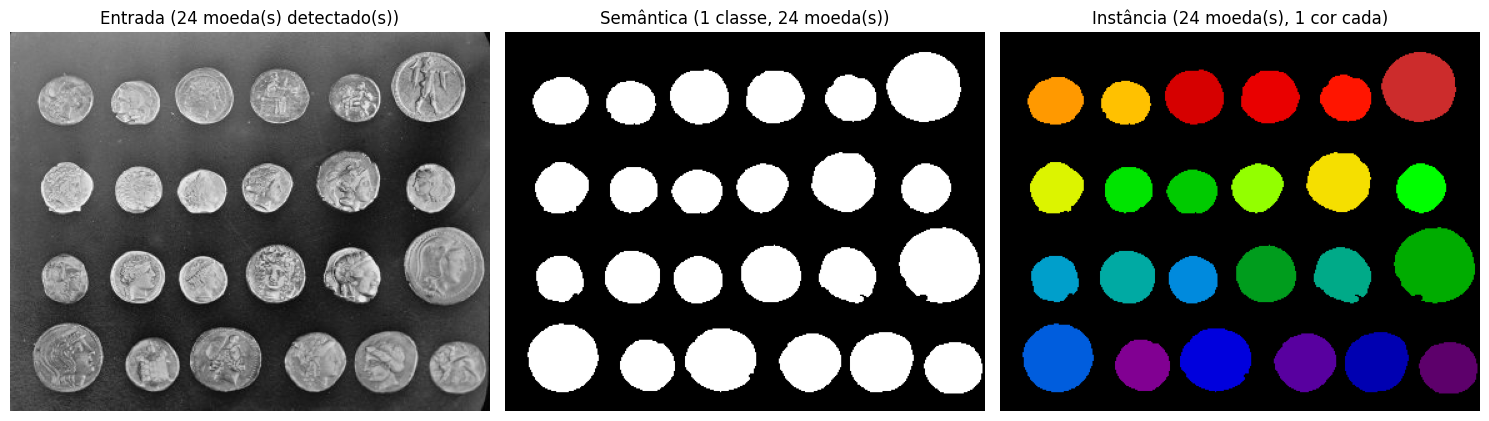

In [25]:
moedas = data.coins()

mascara_sem_moedas, mascara_inst_moedas, contornos_moedas = segmentar(
    moedas, metodo="adaptativo", block_size=101, c=-20, inverter=False, area_min=500
)

print(f"Número de moedas detectadas: {len(contornos_moedas)}")
plotar_comparacao(moedas, mascara_sem_moedas, mascara_inst_moedas, contornos_moedas, nome_objeto="moeda")

## Imagem 2 - `data.binary_blobs()` 

Número de blobs detectados: 23


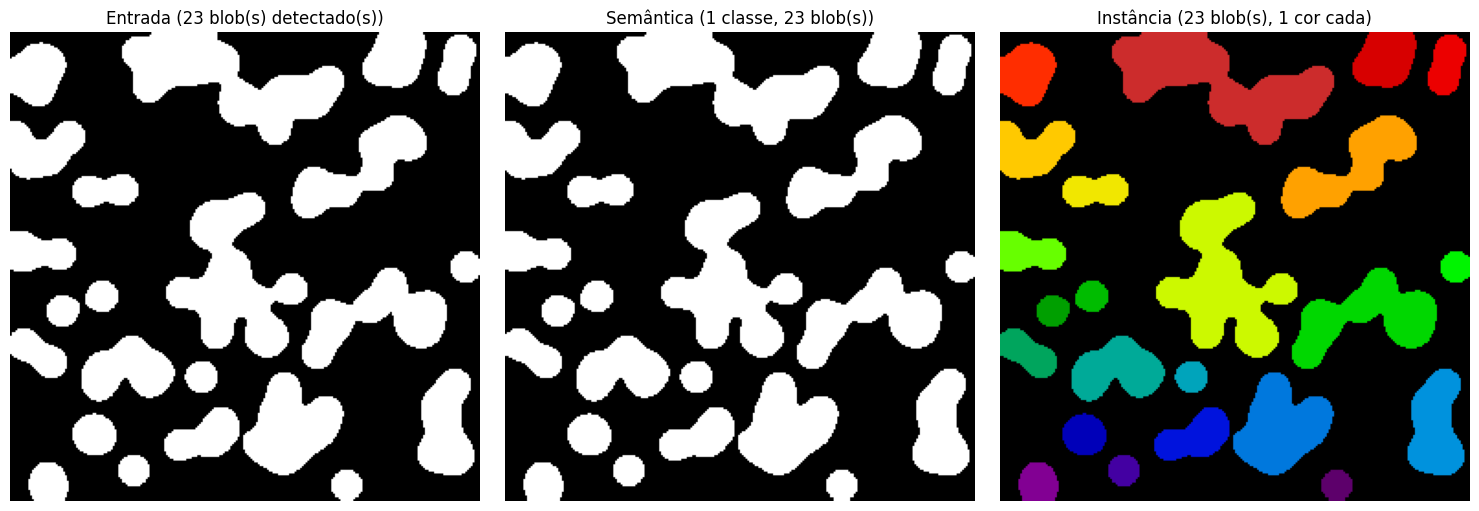

In [26]:
blobs = data.binary_blobs(length=256, blob_size_fraction=0.1, volume_fraction=0.35)
blobs = (blobs.astype(np.uint8)) * 255

mascara_sem_blobs, mascara_inst_blobs, contornos_blobs = segmentar(
    blobs, metodo="otsu", inverter=False, area_min=20
)

print(f"Número de blobs detectados: {len(contornos_blobs)}")
plotar_comparacao(blobs, mascara_sem_blobs, mascara_inst_blobs, contornos_blobs, nome_objeto="blob")

## Comparação e conclusão

**Moedas (`data.coins`)**: os objetos são bem separados entre si (fundo escuro, moedas claras,
sem contato entre elas), então a limiarização adaptativa + contornos consegue isolar cada moeda
corretamente. A segmentação por instância fica muito próxima da semântica, a única diferença visual
é a cor atribuída a cada moeda, mas a contagem de objetos (contornos) está correta.

**Blobs (`data.binary_blobs`)**: o pipeline também funciona, mas como os blobs são gerados
aleatoriamente e vários se tocam, alguns contornos acabam fundindo dois ou mais blobs vizinhos
em uma única instância. Isso faz com que o número de instâncias detectadas nem sempre corresponda
ao número real de blobs gerados.

**Diferença entre as duas segmentações**: na imagem das moedas, semântica e instância praticamente
se equivalem porque os objetos nunca se encostam. Já nos blobs, como eles por vezes se tocam,
a segmentação por instância explicita um problema que a segmentação semântica esconde: na máscara
semântica tudo vira uma única "mancha", enquanto na instância fica visível quando dois blobs foram
unidos erroneamente em uma mesma cor (mesma instância). Ou seja, a instância é mais exigente e mais
informativa quando há objetos próximos/tocando, pois depende de uma separação (conectividade) correta
entre eles, o que a classificação semântica não precisa garantir.